In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import mapclassify
import matplotlib.pyplot as plt


In [2]:
# import geopandas as gpd
# from sklearn.cluster import KMeans
# from sklearn.preprocessing import StandardScaler
# import matplotlib.pyplot as plt

# def kmeans_multi(path_gdf: str, columns: list, n_clusters: int = 3,
#                  colors_list=None, label_names=None):
#     """
#     Apply KMeans clustering on one or more columns in a GeoDataFrame.

#     :param path_gdf: Path to GeoDataFrame (shapefile, GeoJSON, etc.)
#     :param columns: List of column names to use for KMeans
#     :param n_clusters: Number of clusters for KMeans
#     :param colors_list: List of colors for clusters (default ["red","orange","yellow","green"])
#     :param label_names: List of labels for clusters (default ["Low","Medium","High","Very High"])
#     :return: GeoDataFrame with cluster labels
#     """
#     # Defaults
#     if colors_list is None:
#         colors_list = ["red", "orange", "yellow", "green"]
#     if label_names is None:
#         label_names = ["Low", "Medium", "High", "Very High"]

#     # Read GeoDataFrame
#     gdf = gpd.read_file(path_gdf)

#     # ------------------------------
#     # K-Means Clustering (multi-column)
#     # ------------------------------
#     features = gdf[columns].values
#     scaler = StandardScaler()
#     features_scaled = scaler.fit_transform(features)

#     kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
#     gdf["kmeans_cluster"] = kmeans.fit_predict(features_scaled)

#     # Reorder clusters by mean of first column
#     first_col = columns[0]
#     cluster_means = gdf.groupby("kmeans_cluster")[first_col].mean().sort_values()
#     mapping = {cluster: i for i, cluster in enumerate(cluster_means.index)}
#     gdf["kmeans_class"] = gdf["kmeans_cluster"].map(mapping)

#     # Assign labels based on cluster order
#     labels = label_names[:n_clusters]  # use as many as clusters
#     label_dict = {i: labels[i] for i in range(n_clusters)}
#     gdf["kmeans_label"] = gdf["kmeans_class"].map(label_dict)

#     # ------------------------------
#     # Visualization: KMeans map with user-defined colors
#     # ------------------------------
#     fig, ax = plt.subplots(1, 1, figsize=(10, 8))
#     color_map = {label: colors_list[i % len(colors_list)] for i, label in enumerate(labels)}
#     gdf.plot(ax=ax, column="kmeans_label", categorical=True, legend=True,
#              color=gdf["kmeans_label"].map(color_map), edgecolor=None)
#     ax.set_title("KMeans Clustering")
#     ax.axis("off")
#     plt.show()

# #     # ------------------------------
# #     # Histogram for first column with KMeans centers
# #     # ------------------------------
# #     values = gdf[first_col].values
# #     centers = sorted(kmeans.cluster_centers_[:, 0])  # first column for plotting

# #     fig, ax = plt.subplots(figsize=(10, 6))
# #     ax.hist(values, bins=50, color="lightgray", edgecolor="black")
# #     ax.set_title(f"Distribution of '{first_col}'")
# #     ax.set_xlabel(first_col)
# #     ax.set_ylabel("Number of features")

# #     for c in centers:
# #         ax.axvline(c, color="blue", linestyle="--", linewidth=2,
# #                    label="KMeans centroid" if c == centers[0] else "")

# #     ax.legend()
# #     plt.show()

#     # ------------------------------
#     # Counts
#     # ------------------------------
#     print("KMeans class counts:")
#     print(gdf["kmeans_label"].value_counts())

#     return gdf,features_scaled


In [3]:
# import geopandas as gpd
# from sklearn.cluster import KMeans
# from sklearn.preprocessing import StandardScaler
# from sklearn.metrics import silhouette_score
# import matplotlib.pyplot as plt
# import numpy as np

# def kmeans_multi(path_gdf: str, columns: list, k_min: int = 2, k_max: int = 10,
#                  colors_list=None, label_names=None):
#     """
#     Apply KMeans clustering on multiple columns in a GeoDataFrame.
#     Automatically selects the best number of clusters using silhouette score.

#     References:
#     - Rousseeuw, P. J. (1987). *Silhouettes: A graphical aid to the interpretation and validation of cluster analysis.*
#       Journal of Computational and Applied Mathematics, 20, 53–65.
#     """

#     if colors_list is None:
#         colors_list = ["red", "orange", "yellow", "green", "blue", "purple", "brown", "pink", "gray", "cyan"]
#     if label_names is None:
#         label_names = [f"Cluster {i+1}" for i in range(k_max)]

#     # Read GeoDataFrame
#     gdf = gpd.read_file(path_gdf)

#     # Feature scaling
#     features = gdf[columns].values
#     scaler = StandardScaler()
#     features_scaled = scaler.fit_transform(features)

#     # -----------------------------------
#     # Determine best k using silhouette score
#     # -----------------------------------
#     best_k, best_score = None, -1
#     for k in range(k_min, k_max + 1):
#         kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
#         labels = kmeans.fit_predict(features_scaled)
#         score = silhouette_score(features_scaled, labels)
#         print(f"k={k}, silhouette={score:.4f}")
#         if score > best_score:
#             best_k, best_score = k, score

#     print(f"\n Best number of clusters based on silhouette score: {best_k} (score={best_score:.4f})")

#     # Fit KMeans with best k
#     kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
#     gdf["kmeans_cluster"] = kmeans.fit_predict(features_scaled)

#     # Reorder clusters by mean of first column
#     first_col = columns[0]
#     cluster_means = gdf.groupby("kmeans_cluster")[first_col].mean().sort_values()
#     mapping = {cluster: i for i, cluster in enumerate(cluster_means.index)}
#     gdf["kmeans_class"] = gdf["kmeans_cluster"].map(mapping)

#     # Assign labels and colors (auto-adjust length)
#     labels = label_names[:best_k]
#     label_dict = {i: labels[i] for i in range(best_k)}
#     gdf["kmeans_label"] = gdf["kmeans_class"].map(label_dict)
#     color_map = {label: colors_list[i % len(colors_list)] for i, label in enumerate(labels)}

#     # Visualization
#     fig, ax = plt.subplots(1, 1, figsize=(10, 8))
#     gdf.plot(ax=ax, column="kmeans_label", categorical=True, legend=True,
#              color=gdf["kmeans_label"].map(color_map), edgecolor=None)
#     ax.set_title(f"KMeans Clustering (k={best_k})")
#     ax.axis("off")
#     plt.show()

#     print("\nKMeans class counts:")
#     print(gdf["kmeans_label"].value_counts())

#     return gdf, features_scaled, best_k


In [4]:
import geopandas as gpd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def kmeans_multi(
    path_gdf: str,
    columns: list,
    k_min: int = 2,
    k_max: int = 10,
    scaler_type: str = "standard",
    use_pca: bool = False,
    pca_variance: float = 0.95,
    weight_dict: dict = None,
    scoring_metric: str = "davies",  # 'silhouette', 'davies', 'calinski'
    colors_list=None,
    label_names=None
):
    """
    Improved KMeans clustering for multi-feature GeoDataFrames.

    Features:
    - Allows numeric (non-coordinate) geospatial features.
    - Supports StandardScaler or RobustScaler.
    - Optional feature weighting.
    - Optional PCA for dimensionality reduction.
    - Evaluates multiple clustering quality metrics.
    - Selects best k based on chosen metric.
    """

    if colors_list is None:
        colors_list = ["red", "orange", "yellow", "green", "blue", "purple", "brown", "pink", "gray", "cyan"]
    if label_names is None:
        label_names = [f"Cluster {i+1}" for i in range(k_max)]

    # Read GeoDataFrame
    gdf = gpd.read_file(path_gdf)

    # Select features and drop rows with missing data
    features = gdf[columns].dropna()
    gdf = gdf.loc[features.index]  # align
    X = features.values.astype(float)

    # Optional feature weighting
    if weight_dict:
        for col, w in weight_dict.items():
            if col in features.columns:
                X[:, features.columns.get_loc(col)] *= w

    # Scaling
    scaler = StandardScaler() if scaler_type == "standard" else RobustScaler()
    X_scaled = scaler.fit_transform(X)

    # Optional PCA
    if use_pca:
        pca = PCA(n_components=pca_variance)
        X_scaled = pca.fit_transform(X_scaled)
        print(f"PCA reduced features from {len(columns)} → {X_scaled.shape[1]} components")

    # -----------------------------------
    # Evaluate multiple k values
    # -----------------------------------
    results = []
    for k in range(k_min, k_max + 1):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_scaled)

        sil = silhouette_score(X_scaled, labels) if k > 1 else np.nan
        dav = davies_bouldin_score(X_scaled, labels)
        cal = calinski_harabasz_score(X_scaled, labels)
        results.append((k, sil, dav, cal))

        print(f"k={k:2d} | silhouette={sil:.4f} | davies={dav:.4f} | calinski={cal:.2f}")

    results_df = pd.DataFrame(results, columns=["k", "silhouette", "davies", "calinski"])

    # Select best k
    if scoring_metric == "silhouette":
        best_k = results_df.loc[results_df["silhouette"].idxmax(), "k"]
    elif scoring_metric == "calinski":
        best_k = results_df.loc[results_df["calinski"].idxmax(), "k"]
    else:  # default: davies
        best_k = results_df.loc[results_df["davies"].idxmin(), "k"]

    print(f"\nBest k={best_k} based on {scoring_metric} metric")

    # -----------------------------------
    # Fit final model
    # -----------------------------------
    kmeans = KMeans(n_clusters=int(best_k), random_state=42, n_init=10)
    gdf["kmeans_cluster"] = kmeans.fit_predict(X_scaled)

    # Reorder cluster IDs by mean of first column
    first_col = columns[0]
    cluster_means = gdf.groupby("kmeans_cluster")[first_col].mean().sort_values()
    mapping = {cluster: i for i, cluster in enumerate(cluster_means.index)}
    gdf["kmeans_class"] = gdf["kmeans_cluster"].map(mapping)

    # Label & color
    labels = label_names[:int(best_k)]
    gdf["kmeans_label"] = gdf["kmeans_class"].map({i: labels[i] for i in range(int(best_k))})
    color_map = {label: colors_list[i % len(colors_list)] for i, label in enumerate(labels)}

    # -----------------------------------
    # Visualization
    # -----------------------------------
    fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    gdf.plot(ax=ax, column="kmeans_label", categorical=True, legend=True,
             color=gdf["kmeans_label"].map(color_map), edgecolor="none")
    ax.set_title(f"KMeans Clustering (k={best_k}, metric={scoring_metric})", fontsize=13)
    ax.axis("off")
    plt.show()

    print("\nCluster counts:")
    print(gdf["kmeans_label"].value_counts())
    print("\nMetric summary:")
    print(results_df.round(3))

    return gdf, X_scaled, results_df, best_k


PCA reduced features from 10 → 6 components
k= 2 | silhouette=0.3897 | davies=1.0705 | calinski=4281.28
k= 3 | silhouette=0.3926 | davies=1.1847 | calinski=3621.39
k= 4 | silhouette=0.3915 | davies=1.0911 | calinski=3753.47
k= 5 | silhouette=0.3923 | davies=0.8932 | calinski=3782.26
k= 6 | silhouette=0.4037 | davies=0.9430 | calinski=3870.04
k= 7 | silhouette=0.4139 | davies=0.8087 | calinski=3974.48
k= 8 | silhouette=0.3834 | davies=0.8644 | calinski=4130.34
k= 9 | silhouette=0.3723 | davies=0.8954 | calinski=4168.46
k=10 | silhouette=0.3785 | davies=0.8642 | calinski=4293.35

Best k=7 based on davis metric


/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


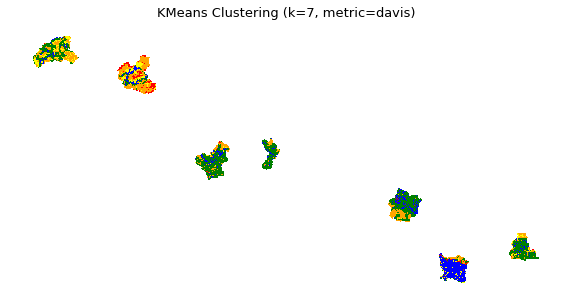


Cluster counts:
Cluster 4    4476
Cluster 2    2720
Cluster 5    1880
Cluster 3     946
Cluster 1     425
Cluster 6      38
Cluster 7       8
Name: kmeans_label, dtype: int64

Metric summary:
    k  silhouette  davies  calinski
0   2       0.390   1.070  4281.279
1   3       0.393   1.185  3621.392
2   4       0.391   1.091  3753.467
3   5       0.392   0.893  3782.264
4   6       0.404   0.943  3870.043
5   7       0.414   0.809  3974.481
6   8       0.383   0.864  4130.339
7   9       0.372   0.895  4168.463
8  10       0.378   0.864  4293.352


In [46]:
# gdf, features_scaled, metrics_df, best_k = kmeans_multi(path_gdf="/home/jovyan/work/data/data_analysis/k-means/shape/Nepal/np_adm2_1k_si_3dg_si_overture_lod1_fb_urban_lu.gpkg", 
#              columns=["PercentBld","PercentLU_",
#                       "mean_Heigh","min_Height","max_Height","std_Height",
#                       "Polygon_Co","PercentL_2","PercentLU1", "PercentL_1"],
#                      # 'mean_hei_1','min_heig_1', 'max_heig_1', 'std_heig_1'], 
#             scoring_metric = "davis",  # 'silhouette', 'davies', 'calinski'
#             use_pca= True
#             )

k= 2 | silhouette=0.5786 | davies=0.5575 | calinski=5960.15
k= 3 | silhouette=0.5983 | davies=0.8777 | calinski=5805.67
k= 4 | silhouette=0.6025 | davies=0.5455 | calinski=5904.77
k= 5 | silhouette=0.5494 | davies=0.7805 | calinski=6363.13
k= 6 | silhouette=0.5774 | davies=0.8399 | calinski=6676.30
k= 7 | silhouette=0.5867 | davies=0.7999 | calinski=6865.59
k= 8 | silhouette=0.5752 | davies=0.7924 | calinski=6851.60
k= 9 | silhouette=0.5815 | davies=0.8519 | calinski=6776.30
k=10 | silhouette=0.5826 | davies=0.8042 | calinski=6633.53

Best k=4 based on davis metric


/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


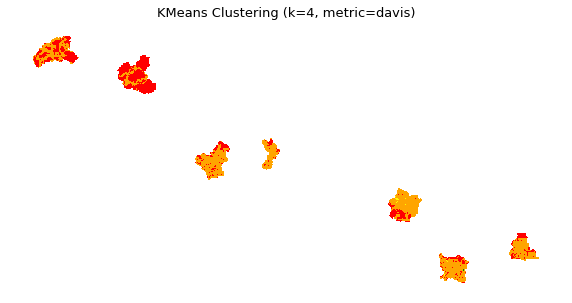


Cluster counts:
Cluster 2    6412
Cluster 1    4035
Cluster 3      38
Cluster 4       8
Name: kmeans_label, dtype: int64

Metric summary:
    k  silhouette  davies  calinski
0   2       0.579   0.558  5960.154
1   3       0.598   0.878  5805.674
2   4       0.602   0.545  5904.771
3   5       0.549   0.781  6363.129
4   6       0.577   0.840  6676.298
5   7       0.587   0.800  6865.591
6   8       0.575   0.792  6851.595
7   9       0.581   0.852  6776.304
8  10       0.583   0.804  6633.533


In [5]:
gdf, features_scaled, metrics_df, best_k = kmeans_multi(path_gdf="/home/jovyan/work/data/data_analysis/k-means/shape/Nepal/np_adm2_1k_si_3dg_si_overture_lod1_fb_urban_lu.gpkg", 
             columns=["PercentBld","PercentLU_",
                      "mean_Heigh","min_Height","max_Height","std_Height",
                      "Polygon_Co",],
                     # 'mean_hei_1','min_heig_1', 'max_heig_1', 'std_heig_1'], 
            scoring_metric = "davis",  # 'silhouette', 'davies', 'calinski'
            use_pca= False
            )

In [6]:
# gdf.to_file("/home/jovyan/work/data/data_analysis/k-means/k7_pca_davis_bldgs.gpkg")

/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,


In [49]:
gdf

,PageName,PageNumber,ADM2_NAME,ADM1_NAME,ADM0_NAME,GUID,ADM2_ALTNA,ADM1_VIZ_N,ADM2_VIZ_N,ADM0_VIZ_N,...,PercentBld,PercentLU1,PercentL_1,PercentL_2,Shape__Are,Shape__Len,geometry,kmeans_cluster,kmeans_class,kmeans_label
0,A693,1,SIRAHA,PROVINCE 2,NEPAL,{5ea79d2d-2236-4e97-91bd-fa8445f7dc95},None,Province 2,Siraha,Nepal,...,0.141776,9.512888,0.000000,0.000000,0.000081,0.035973,"MULTIPOLYGON (((86.46486 26.55093, 86.46486 26...",4,3,Cluster 4
1,A694,2,SIRAHA,PROVINCE 2,NEPAL,{5ea79d2d-2236-4e97-91bd-fa8445f7dc95},None,Province 2,Siraha,Nepal,...,2.861530,66.224328,0.000000,0.000000,0.000081,0.035973,"MULTIPOLYGON (((86.47386 26.55093, 86.47386 26...",1,4,Cluster 5
2,A695,3,SIRAHA,PROVINCE 2,NEPAL,{5ea79d2d-2236-4e97-91bd-fa8445f7dc95},None,Province 2,Siraha,Nepal,...,0.004500,52.869704,0.000000,0.000000,0.000081,0.035973,"MULTIPOLYGON (((86.48285 26.55093, 86.48285 26...",3,2,Cluster 3
3,A696,4,SIRAHA,PROVINCE 2,NEPAL,{5ea79d2d-2236-4e97-91bd-fa8445f7dc95},None,Province 2,Siraha,Nepal,...,0.824253,53.875869,0.000000,0.000000,0.000081,0.035973,"MULTIPOLYGON (((86.49184 26.55093, 86.49184 26...",1,4,Cluster 5
4,B691,5,SIRAHA,PROVINCE 2,NEPAL,{5ea79d2d-2236-4e97-91bd-fa8445f7dc95},None,Province 2,Siraha,Nepal,...,0.000000,2.561359,0.000000,0.000000,0.000081,0.035973,"MULTIPOLYGON (((86.44688 26.55992, 86.44688 26...",4,3,Cluster 4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10488,MM59,10489,BAITADI,SUDUR PASHCHIM,NEPAL,{1c02b956-e09a-4ef6-9988-d9d729719597},None,Sudur Pashchim,Baitadi,Nepal,...,0.000000,37.561686,9.131538,53.753691,0.000081,0.035973,"MULTIPOLYGON (((80.76316 29.69855, 80.76316 29...",3,2,Cluster 3
10489,MM60,10490,BAITADI,SUDUR PASHCHIM,NEPAL,{1c02b956-e09a-4ef6-9988-d9d729719597},None,Sudur Pashchim,Baitadi,Nepal,...,0.034972,13.179538,5.554234,79.171365,0.000081,0.035973,"MULTIPOLYGON (((80.77215 29.69855, 80.77215 29...",0,1,Cluster 2
10490,MM61,10491,BAITADI,SUDUR PASHCHIM,NEPAL,{1c02b956-e09a-4ef6-9988-d9d729719597},None,Sudur Pashchim,Baitadi,Nepal,...,0.000000,2.730047,2.165210,89.244307,0.000081,0.035973,"MULTIPOLYGON (((80.78115 29.69855, 80.78115 29...",0,1,Cluster 2
10491,MN57,10492,BAITADI,SUDUR PASHCHIM,NEPAL,{1c02b956-e09a-4ef6-9988-d9d729719597},None,Sudur Pashchim,Baitadi,Nepal,...,0.000000,4.989835,25.984803,69.010363,0.000081,0.035973,"MULTIPOLYGON (((80.74518 29.70755, 80.74518 29...",6,0,Cluster 1


In [48]:
#sample size

In [7]:
import pandas as pd

N_total = 150

# Count tiles per region
region_counts = gdf['ADM2_NAME'].value_counts()
total_tiles = region_counts.sum()

# Samples per region
samples_per_region = (region_counts / total_tiles * N_total).round().astype(int)

# Class proportions per region
class_proportions_region = gdf.groupby('ADM2_NAME')['kmeans_class'].value_counts(normalize=True)

# Multiply: propagate samples_per_region to each class in the region
samples_per_class_region = class_proportions_region.copy()
for (region, cls), prop in class_proportions_region.items():
    samples_per_class_region.loc[(region, cls)] = round(prop * samples_per_region.loc[region])

# Convert to int
samples_per_class_region = samples_per_class_region.astype(int)


In [8]:
samples_per_class_region

ADM2_NAME       kmeans_class
BAITADI         0               14
                1               13
DHANKUTA        1               12
                0                4
                2                0
KALIKOT         0               23
                1                6
KAVREPALANCHOK  1               19
                0                5
                2                0
PYUTHAN         1               27
                0                7
                2                0
SIRAHA          1               15
                0                4
                2                0
                3                0
Name: kmeans_class, dtype: int64

In [84]:
sampled_df = pd.DataFrame()

for (region, cls), n_samples in samples_per_class_region.items():
    subset = gdf[(gdf['ADM2_NAME'] == region) & (gdf['kmeans_class'] == cls)]
    if n_samples > len(subset):
        n_samples = len(subset)  # handle rare classes
    sampled_df = pd.concat([sampled_df, subset.sample(n=n_samples, random_state=42)])

sampled_df = sampled_df.reset_index(drop=True)


In [87]:
gpd.GeoDataFrame(sampled_df,geometry="geometry").to_file("/home/jovyan/work/data/data_analysis/k-means/sampling_k7_pca_davis.gpkg")

/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,


In [72]:
import pandas as pd

# Total number of samples
N_total = 150

# Compute global class proportions
class_counts = gdf['kmeans_class'].value_counts()
class_proportions = class_counts / class_counts.sum()

# Compute number of samples per class
samples_per_class = (class_proportions * N_total).round().astype(int)

# Sample proportionally by class
sampled_df = pd.DataFrame()

for cls, n_samples in samples_per_class.items():
    subset = gdf[gdf['kmeans_class'] == cls]
    if n_samples > len(subset):
        n_samples = len(subset)  # handle rare classes
    sampled_df = pd.concat([sampled_df, subset.sample(n=n_samples, random_state=42)])

# Reset index
sampled_df = sampled_df.reset_index(drop=True)

# Check sampled proportions
print(sampled_df['kmeans_class'].value_counts(normalize=True))


3    0.423841
1    0.258278
4    0.178808
2    0.092715
0    0.039735
5    0.006623
Name: kmeans_class, dtype: float64


In [76]:
gpd.GeoDataFrame(sampled_df,geometry="geometry").to_file("/home/jovyan/work/data/data_analysis/k-means/sampling_k7_pca_davis.gpkg")

/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,


In [69]:
import pandas as pd

# Example DataFrame: each row is a grid cell, with 'region' and 'class' columns
# df = pd.DataFrame({'region': [...], 'class': [...]})

# Count number of cells per class
class_counts = gdf['kmeans_class'].value_counts()
# print(class_counts)

# Compute proportion
class_proportions = class_counts / class_counts.sum()
# print(class_proportions)

class_proportions_region = gdf.groupby('ADM2_NAME')['kmeans_class'].value_counts(normalize=True)

N = 150  # total number of samples
samples_per_class = (class_proportions * N).round().astype(int)

sampled_df = gdf.groupby(['ADM2_NAME', 'kmeans_class'], group_keys=False).apply(
    lambda x: x.sample(n=samples_per_class_region.loc[x.name], random_state=42)
)


NameError: name 'samples_per_class_region' is not defined

In [67]:
sampled_df = gdf.groupby(['ADM2_NAME', 'kmeans_class'], group_keys=False).apply(
    lambda x: x.sample(n=samples_per_class_region.loc[x.name], random_state=42)
)

NameError: name 'samples_per_class_region' is not defined

In [13]:
gdf=gpd.read_file("/home/jovyan/work/data/data_analysis/k-means/shape/Nepal/np_adm2_1k_si_3dg_si_overture_lod1_fb_urban_lu.gpkg")
gdf[["PercentBld","PercentLU_",
     "mean_Heigh","min_Height","max_Height","std_Height",
    "Polygon_Co",
    'mean_hei_1','min_heig_1', 'max_heig_1', 'std_heig_1']]
gdf.columns

#PercentBld -> OM Built up area 
#PercentLU_ -> LU Built up area 
#"mean_Heigh","min_Height","max_Height","std_Height" ->3DG
#'Polygon_Co' -> oVERTURE COUNT OF P OLYGONS
#'mean_hei_1','min_heig_1', 'max_heig_1', 'std_heig_1' ->loD

Index(['PageName', 'PageNumber', 'ADM2_NAME', 'ADM1_NAME', 'ADM0_NAME', 'GUID',
       'ADM2_ALTNA', 'ADM1_VIZ_N', 'ADM2_VIZ_N', 'ADM0_VIZ_N', 'Grid_Statu',
       'Status', 'mean_Heigh', 'min_Height', 'max_Height', 'std_Height',
       'sum_Area_S', 'Polygon_Co', 'sum_Area_1', 'Polygon__1', 'mean_hei_1',
       'min_heig_1', 'max_heig_1', 'std_heig_1', 'sum_Shape_', 'sum_Area_2',
       'Polygon__2', 'sum_Area_3', 'OBJECTID_1', 'PAGENAME_1', 'WATER', 'SNOW',
       'FOREST', 'RIVERBED', 'BUILT_UP', 'CROPLAND', 'BARE_SOIL', 'BARE_ROCK',
       'GRASSLAND', 'OTHER_WOOD', 'Calc_Area_', 'PercentLU_', 'PercentBld',
       'PercentLU1', 'PercentL_1', 'PercentL_2', 'Shape__Are', 'Shape__Len',
       'geometry'],
      dtype='object')

In [14]:
gdf = gdf[["PercentBld","PercentLU_",
     "mean_Heigh","min_Height","max_Height","std_Height",
    "Polygon_Co",
    'mean_hei_1','min_heig_1', 'max_heig_1', 'std_heig_1']]


In [ ]:
kmeans_multi(path_gdf="data/data_analysis/k-means/shape/Nepal/np_adm2_1k_si_3dg_si_overture_lod1_fb_urban_lu.gpkg", 
             columns=["PercentBld","PercentLU_",
                      "mean_Heigh","min_Height","max_Height","std_Height",
                      "Polygon_Co",
                      'mean_hei_1','min_heig_1', 'max_heig_1', 'std_heig_1'], 
             n_clusters= 6,)

["MEAN_heigh","MIN_height","MAX_height","SD_height",
                     "sum_Area_S","sum_Area_1","sum_area_2","Urban_FB",
                      "OvertureMa","Overture_1"]

prcoessing Hilmand


/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


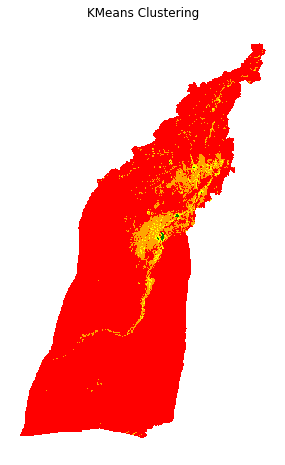

KMeans class counts:
Low          64340
Medium        5135
High           808
Very High       50
Name: kmeans_label, dtype: int64
prcoessing kandahar


/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


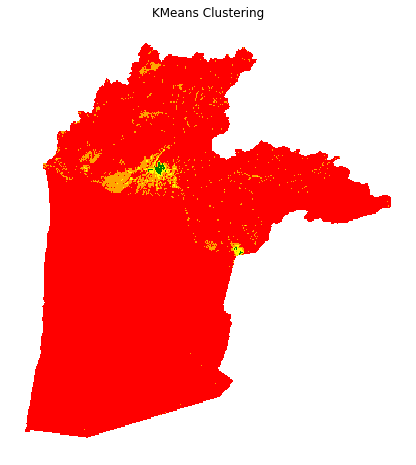

KMeans class counts:
Low          61222
Medium        2068
High           223
Very High       76
Name: kmeans_label, dtype: int64
prcoessing nimroz


/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


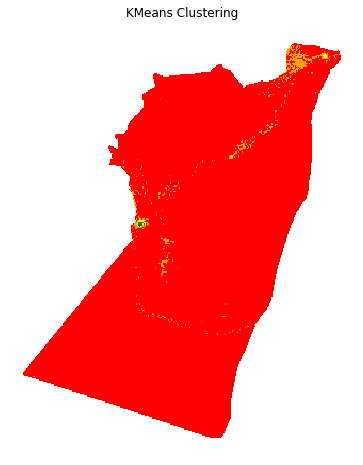

KMeans class counts:
Low          46947
Medium         788
High            35
Very High       18
Name: kmeans_label, dtype: int64
prcoessing shahjoy


/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


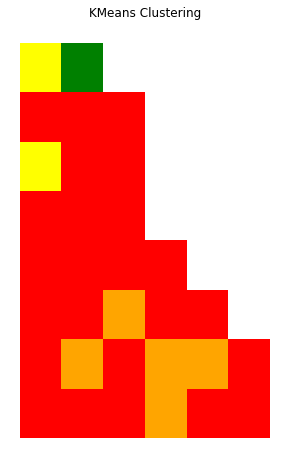

KMeans class counts:
Low          24
Medium        5
High          2
Very High     1
Name: kmeans_label, dtype: int64
prcoessing urzugan


/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


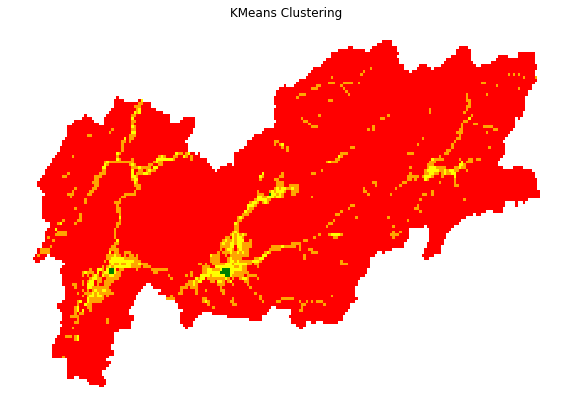

KMeans class counts:
Low          11943
Medium         908
High           280
Very High       14
Name: kmeans_label, dtype: int64
prcoessing zabul


/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


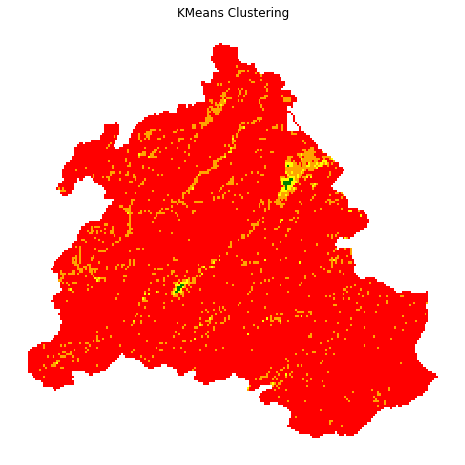

KMeans class counts:
Low          19199
Medium        1384
High           129
Very High       22
Name: kmeans_label, dtype: int64


In [12]:
regions = ["BAITADI","DHANKUTA","KABHREPALANCHOK",
          "KALIKOT","PARBAT","PYUTHAN","SIRAHA"]
import geopandas as gpd

for r in regions:
    print(f"prcoessing {r}")
    path = f"/home/jovyan/work/data/project/tiles_data/{r}_grid_1km.gpkg"
    gdf,features_scaled = kmeans_multi(path_gdf=path,
             columns=["OvertureMa","Overture_1"], 
             n_clusters = 4,
                        )
    # print(type(gdf))
    # dest_path = f"/home/jovyan/work/data/project/tiles_2_att/{r}_class.gpkg"
    # gdf.to_file(dest_path)
    # print(f"completed , saved to {dest_path}")

/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


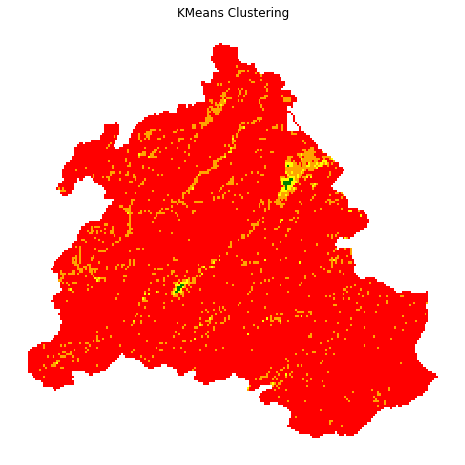

KMeans class counts:
Low          19199
Medium        1384
High           129
Very High       22
Name: kmeans_label, dtype: int64


In [5]:
gdf,features_scaled = kmeans_multi(path_gdf="/home/jovyan/work/data/project/tiles_data/zabul_grid_1km.gpkg",
             columns=["OvertureMa","Overture_1"], 
             n_clusters = 4,
             # colors_list=["red", "orange", "yellow", "green","blue","pink"],
             # label_names=["1","2","3","4","5","6"]
                        )

In [41]:
import geopandas as gpd
region = "zabul"
test.to_file(f"/home/jovyan/work/data/project/classified_tiles/2att/{region}_class.gpkg")

/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,


In [ ]:
# import geopandas as gpd
# import pandas as pd
# import numpy as np
# from sklearn.cluster import KMeans
# import mapclassify
# import matplotlib.pyplot as plt

# def jenks_k_means(path_gdf: str, col_name: str):
#     gdf = gpd.read_file(path_gdf)
#     col = col_name

#     # Masks
#     mask_zero = gdf[col] == 0
#     mask_nonzero = gdf[col] > 0

#     # --------------------------------------------------
#     #  Jenks Natural Breaks (non-zero only)
#     # --------------------------------------------------
#     jenks = mapclassify.NaturalBreaks(y=gdf.loc[mask_nonzero, col], k=3)

#     gdf.loc[mask_nonzero, "jenks_class"] = jenks.yb
#     jenks_labels = {0: "Low", 1: "Medium", 2: "High"}
#     gdf.loc[mask_nonzero, "jenks_label"] = gdf.loc[mask_nonzero, "jenks_class"].map(jenks_labels)
#     gdf.loc[mask_zero, "jenks_label"] = "Zero"

#     # --------------------------------------------------
#     #  K-Means Clustering (non-zero only)
#     # --------------------------------------------------
#     values = gdf.loc[mask_nonzero, col].values.reshape(-1, 1)
#     kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
#     gdf.loc[mask_nonzero, "kmeans_cluster"] = kmeans.fit_predict(values)

#     # Reorder clusters by mean % built-up
#     cluster_means = gdf.loc[mask_nonzero].groupby("kmeans_cluster")[col].mean().sort_values()
#     mapping = {cluster: i for i, cluster in enumerate(cluster_means.index)}
#     gdf.loc[mask_nonzero, "kmeans_class"] = gdf.loc[mask_nonzero, "kmeans_cluster"].map(mapping)

#     kmeans_labels = {0: "Low", 1: "Medium", 2: "High"}
#     gdf.loc[mask_nonzero, "kmeans_label"] = gdf.loc[mask_nonzero, "kmeans_class"].map(kmeans_labels)
#     gdf.loc[mask_zero, "kmeans_label"] = "Zero"

#     # --------------------------------------------------
#     # Visualization: side-by-side maps
#     # --------------------------------------------------
#     fig, axes = plt.subplots(1, 2, figsize=(16, 8))

#     colors = {"Zero": "lightgray", "Low": "green", "Medium": "yellow", "High": "red"}

#     # KMeans map
#     gdf.plot(ax=axes[0], column="kmeans_label", categorical=True, legend=True,
#              color=gdf["kmeans_label"].map(colors), edgecolor=None)
#     axes[0].set_title("KMeans Clustering (k=3 + Zero)")
#     axes[0].axis("off")

#     # Jenks map
#     gdf.plot(ax=axes[1], column="jenks_label", categorical=True, legend=True,
#              color=gdf["jenks_label"].map(colors), edgecolor=None)
#     axes[1].set_title("Jenks Natural Breaks (+ Zero)")
#     axes[1].axis("off")

#     plt.tight_layout()
#     plt.show()

#     # --------------------------------------------------
#     # Histogram with Jenks breaks + KMeans centers
#     # --------------------------------------------------
#     values_nonzero = gdf.loc[mask_nonzero, col].values
#     jenks_breaks = jenks.bins
#     centers = sorted(kmeans.cluster_centers_.flatten())

#     fig, ax = plt.subplots(figsize=(10, 6))
#     ax.hist(values_nonzero, bins=50, color="lightgray", edgecolor="black")
#     ax.set_title("% Built-up Area Distribution (non-zero)")
#     ax.set_xlabel("% Built-up")
#     ax.set_ylabel("Number of tiles")

#     # Jenks breaks
#     for b in jenks_breaks:
#         ax.axvline(b, color="red", linestyle="-", linewidth=2, label="Jenks break" if b == jenks_breaks[0] else "")

#     # KMeans centers
#     for c in centers:
#         ax.axvline(c, color="blue", linestyle="--", linewidth=2, label="KMeans centroid" if c == centers[0] else "")

#     ax.legend()
#     plt.show()

#     # --------------------------------------------------
#     # Counts
#     # --------------------------------------------------
#     print("KMeans class counts:")
#     print(gdf["kmeans_label"].value_counts())

#     print("\nJenks class counts:")
#     print(gdf["jenks_label"].value_counts())

#     return gdf


In [ ]:
# test = jenks_k_means(
#     path_gdf = "/home/jovyan/work/data/project/tiles_data/zabul_grid_1km.gpkg",
#     col_name ="Overture_1"
#     )

In [26]:
import geopandas as gpd
region = "zabul"
test.to_file(f"/home/jovyan/work/data/project/classified_tiles/{region}_class.gpkg")

/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,


In [61]:
# def jenks_k_means(
#     path_gdf : str , #path to geodataframe to read with the statistical data
#     col_name : str , #name of the oclumn to run calculation on
#     ):
#     gdf = gpd.read_file(path_gdf)
#     col = col_name
    
#     # --------------------------------------------------
#     #  Jenks Natural Breaks
#     # --------------------------------------------------
#     # k=3 means 3 groups (low, medium, high)
#     jenks = mapclassify.NaturalBreaks(y=gdf[col], k=3)

#     # Assign class (0=low, 1=med, 2=high)
#     gdf["jenks_class"] = jenks.yb

#     # Give labels
#     jenks_labels = {0: "Low", 1: "Medium", 2: "High"}
#     gdf["jenks_label"] = gdf["jenks_class"].map(jenks_labels)

#     # print("\nJenks Natural Breaks thresholds:", jenks.bins)
#     # print("Jenks class counts:")
#     # print(gdf["jenks_label"].value_counts())

#     # --------------------------------------------------
#     # OPTION B: K-Means Clustering
#     # --------------------------------------------------
#     values = gdf[col].values.reshape(-1, 1)
#     kmeans = KMeans(n_clusters=3, random_state=42, n_init=100)
#     gdf["kmeans_cluster"] = kmeans.fit_predict(values)

#     # Reorder clusters by mean % built-up
#     cluster_means = gdf.groupby("kmeans_cluster")[col].mean().sort_values()
#     mapping = {cluster: i for i, cluster in enumerate(cluster_means.index)}
#     gdf["kmeans_class"] = gdf["kmeans_cluster"].map(mapping)

#     kmeans_labels = {0: "Low", 1: "Medium", 2: "High"}
#     gdf["kmeans_label"] = gdf["kmeans_class"].map(kmeans_labels)

#     # --------------------------------------------------
#     # 3. Map Visualization (side by side)
#     # --------------------------------------------------
#     fig, axes = plt.subplots(1, 2, figsize=(16, 8))

#     colors = {"Low": "green", "Medium": "yellow", "High": "red"}

#     # KMeans map on the left
#     gdf.plot(ax=axes[0], column="kmeans_label", categorical=True, legend=True,
#              color=gdf["kmeans_label"].map(colors), edgecolor=None)
#     axes[0].set_title("KMeans Clustering (k=3)")
#     axes[0].axis("off")

#     # Jenks map on the right
#     gdf.plot(ax=axes[1], column="jenks_label", categorical=True, legend=True,
#              color=gdf["jenks_label"].map(colors), edgecolor=None)
#     axes[1].set_title("Jenks Natural Breaks")
#     axes[1].axis("off")

#     plt.tight_layout()
#     plt.show()
    
#     # Plot Jenks breaks (solid lines)
#     for b in jenks_breaks:
#         ax.axvline(b, color="red", linestyle="-", linewidth=2, label="Jenks break" if b==jenks_breaks[0] else "")

#     # Plot KMeans centers (dashed lines)
#     for c in centers:
#         ax.axvline(c, color="blue", linestyle="--", linewidth=2, label="KMeans centroid" if c==centers[0] else "")

#     # Legend
#     ax.legend()
#     plt.show()

#     # Count of tiles per class for KMeans
#     print("KMeans class counts:")
#     print(gdf["kmeans_label"].value_counts())

#     # Count of tiles per class for Jenks
#     print("\nJenks class counts:")
#     print(gdf["jenks_label"].value_counts())
    
#     return gdf

/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(
/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


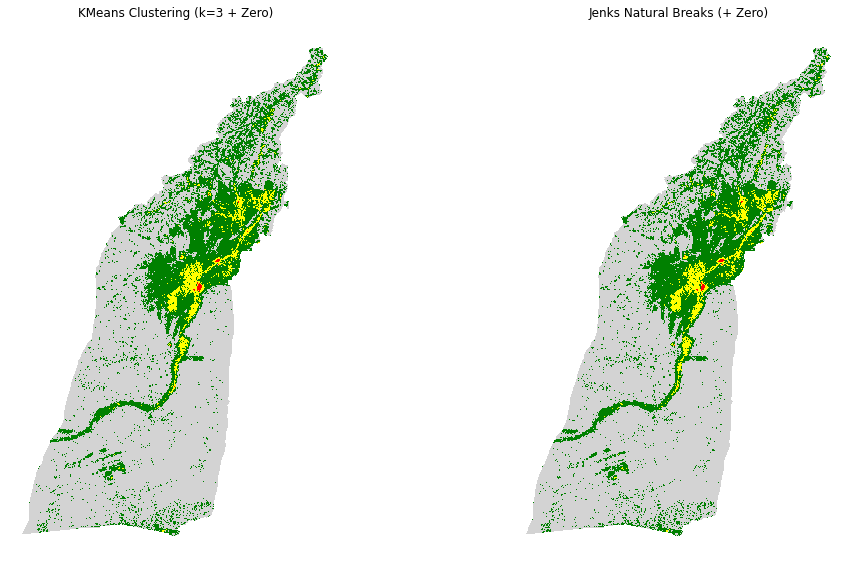

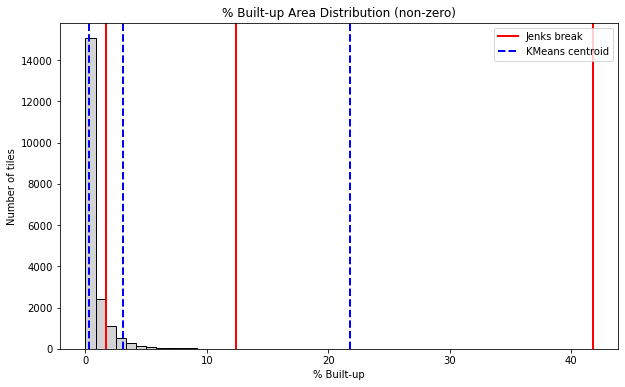

KMeans class counts:
Zero      50480
Low       17542
Medium     2253
High         58
Name: kmeans_label, dtype: int64

Jenks class counts:
Zero      50480
Low       17545
Medium     2251
High         57
Name: jenks_label, dtype: int64


In [27]:
test = jenks_k_means(
    path_gdf = "/home/jovyan/work/data/project/tiles_data/Hilmand_grid_1km.gpkg",
    col_name ="Overture_1"
    )

In [42]:
gdf = gpd.read_file("/home/jovyan/work/data/project/tiles_data/kandahar_grid_1km.gpkg")

In [43]:
col = "Overture_1"

In [44]:
# --------------------------------------------------
# OPTION A: Jenks Natural Breaks
# --------------------------------------------------
# k=3 means 3 groups (low, medium, high)
jenks = mapclassify.NaturalBreaks(y=gdf[col], k=3)

# Assign class (0=low, 1=med, 2=high)
gdf["jenks_class"] = jenks.yb

# Give labels
jenks_labels = {0: "Low", 1: "Medium", 2: "High"}
gdf["jenks_label"] = gdf["jenks_class"].map(jenks_labels)

print("\nJenks Natural Breaks thresholds:", jenks.bins)
print("Jenks class counts:")
print(gdf["jenks_label"].value_counts())


Jenks Natural Breaks thresholds: [ 3.84174489 18.44582482 63.84676139]
Jenks class counts:
Low       63105
Medium      400
High         84
Name: jenks_label, dtype: int64


/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


(7162480.508675002, 7565531.711624999, 3401256.717104998, 3837534.9065950024)

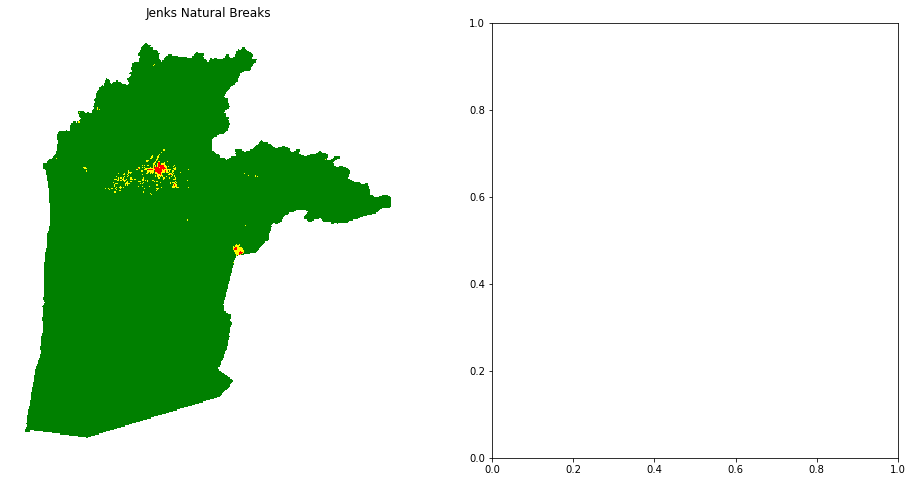

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Define colors
colors = {"Low": "green", "Medium": "yellow", "High": "red"}

# Jenks map
gdf.plot(ax=axes[0], column="jenks_label", categorical=True, legend=True,
         color=gdf["jenks_label"].map(colors), edgecolor=None)
axes[0].set_title("Jenks Natural Breaks")
axes[0].axis("off")

In [46]:
# --------------------------------------------------
# OPTION B: K-Means Clustering
# --------------------------------------------------
values = gdf[col].values.reshape(-1, 1)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=100)
gdf["kmeans_cluster"] = kmeans.fit_predict(values)

# Reorder clusters by mean % built-up
cluster_means = gdf.groupby("kmeans_cluster")[col].mean().sort_values()
mapping = {cluster: i for i, cluster in enumerate(cluster_means.index)}
gdf["kmeans_class"] = gdf["kmeans_cluster"].map(mapping)

kmeans_labels = {0: "Low", 1: "Medium", 2: "High"}
gdf["kmeans_label"] = gdf["kmeans_class"].map(kmeans_labels)




In [47]:
# Plot KMeans classes

colors = {"Low": "green", "Medium": "yellow", "High": "red"}
gdf.plot(ax=axes[0], column="kmeans_label", categorical=True, legend=True,
         color=gdf["kmeans_label"].map(colors), edgecolor=None)

axes[0].set_title("KMeans Clustering (k=3)")
axes[0].axis("off")

plt.tight_layout()
plt.show()

/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


<Figure size 432x288 with 0 Axes>

/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(
/opt/conda/lib/python3.9/site-packages/geopandas/plotting.py:644: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


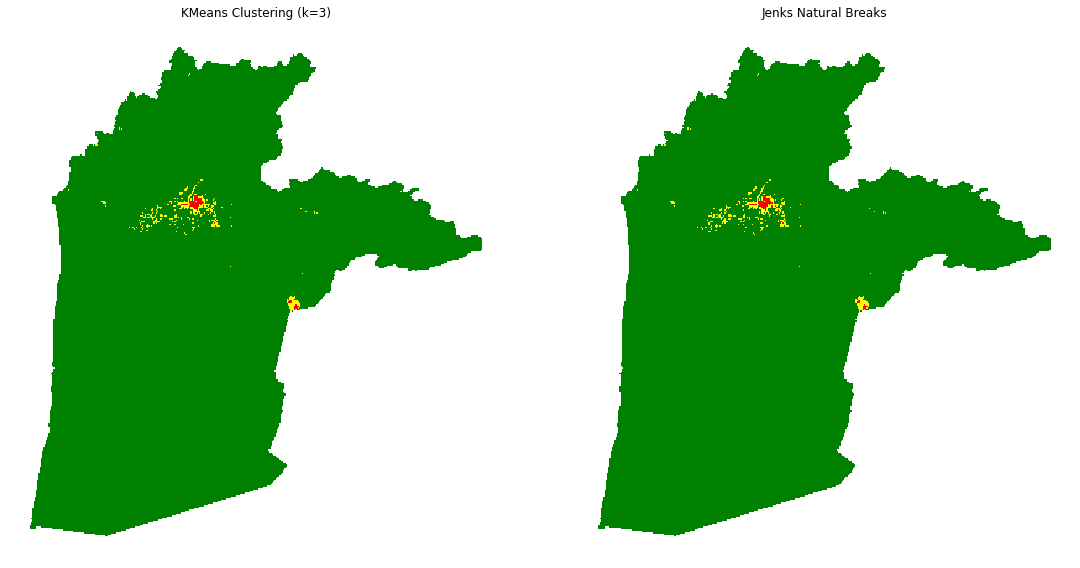

In [48]:
# --------------------------------------------------
# 3. Map Visualization (side by side)
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

colors = {"Low": "green", "Medium": "yellow", "High": "red"}

# KMeans map on the left
gdf.plot(ax=axes[0], column="kmeans_label", categorical=True, legend=True,
         color=gdf["kmeans_label"].map(colors), edgecolor=None)
axes[0].set_title("KMeans Clustering (k=3)")
axes[0].axis("off")

# Jenks map on the right
gdf.plot(ax=axes[1], column="jenks_label", categorical=True, legend=True,
         color=gdf["jenks_label"].map(colors), edgecolor=None)
axes[1].set_title("Jenks Natural Breaks")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [49]:
# Count of tiles per class for KMeans
print("KMeans class counts:")
print(gdf["kmeans_label"].value_counts())

# Count of tiles per class for Jenks
print("\nJenks class counts:")
print(gdf["jenks_label"].value_counts())

KMeans class counts:
Low       63106
Medium      399
High         84
Name: kmeans_label, dtype: int64

Jenks class counts:
Low       63105
Medium      400
High         84
Name: jenks_label, dtype: int64


In [9]:
import geopandas as gpd

gdf = gpd.read_file("/home/jovyan/work/predictions/afghanistan/south_afghanistan/B7_2025/BATCH1_try2/geojson/predicted_buildings.geojson")
gdf.to_file("/home/jovyan/work/predictions/afghanistan/south_afghanistan/B7_2025/BATCH1_try2/geojson/batch1_south_afg.gpkg")

/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,
